# Training and Test Errors, Cross-Validation, Pipelines

In [24]:
import pandas as pd
import numpy as np

from plotnine import *

**Use scikit-learn, including pipelines, whenever possible.**

## Ames Housing Data


We have fit different regression models to predict house prices (SalePrice, not log). Now we will evaluate models by estimating their prediction error.

In [25]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


Since all of the houses in the data set have a SalePrice, we'll include all the observations in the training data. We'll start with a basic linear regression model with a few features.

In [26]:
X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]]

y_train = df_ames["SalePrice"]

In [27]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(
    X=X_train,
    y=y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 118.1 ,-29994.96, 26728.53, 1271.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.694e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


1. Explain conceptually what the "fit" step does. What is the output?

It uses the training data to learn the model’s coefficients and intercept. The result is a fitted model that can make predictions.

2. Explain conceptually how you would compute the *training* RMSE (root mean square error) of this model.

Predict prices for the training houses, find the difference between each predicted and actual price, square those differences, average them, then take the square root.

3. Interpret the *training RMSE*. Is it big or small? What could you use as a rough benchmark for comparison?

The model’s training RMSE is $51,350.42. That means its prediction errors on the training houses are about $51,350 in RMSE terms. This is a sizable dollar amount, but it is lower than the average-price benchmark RMSE of $79,873.06, so the model predicts the training houses better than simply predicting the average sale price for every house.

In [28]:
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

basic_features = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
X_basic = df_ames[basic_features]
y_basic = df_ames["SalePrice"]

# Fit the original four-feature model again
model1 = LinearRegression()
model1.fit(X_basic, y_basic)

# Calculate its training RMSE
train_predictions = model1.predict(X_basic)
train_rmse = np.sqrt(mean_squared_error(y_basic, train_predictions))

# Benchmark: predict the average sale price for every house
baseline_predictions = np.repeat(y_basic.mean(), len(y_basic))
baseline_rmse = np.sqrt(mean_squared_error(y_basic, baseline_predictions))

print(f"Model training RMSE: ${train_rmse:,.2f}")
print(f"Average-price baseline RMSE: ${baseline_rmse:,.2f}")

Model training RMSE: $51,350.42
Average-price baseline RMSE: $79,873.06


4. Suppose we add more features like "TotRms AbvGrd" and fit a new model. Would the *training* RMSE increase or decrease? Why is comparing the *training* RMSE of these two models not useful?

Training RMSE will always decrease or stay the same when we add a feature; it can never increase, because least squares could always set the new coefficient to 0 and get the old fit back. Here it dropped from $51,350.42 to $51,350.40. Comparing training RMSE isn't useful because it will always favor the bigger model, even when the extra feature is only fitting noise. It tells us nothing about how well the model predicts new houses.

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

features_4 = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
features_5 = features_4 + ["TotRms AbvGrd"]

data_4 = df_ames[features_5 + ["SalePrice"]].dropna()
y_4 = data_4["SalePrice"]

for name, features in [
    ("Original model", features_4),
    ("Model with TotRms AbvGrd", features_5)
]:
    model = LinearRegression()
    model.fit(data_4[features], y_4)
    predictions = model.predict(data_4[features])
    rmse = np.sqrt(mean_squared_error(y_4, predictions))
    print(f"{name} training RMSE: ${rmse:,.2f}")

Original model training RMSE: $51,350.42
Model with TotRms AbvGrd training RMSE: $51,350.40


5. If we fit a 1-nearest neighbor model, what should the *training* RMSE be?

The training RMSE should be 0. Each training house's nearest neighbor is itself, so the model predicts its own sale price exactly. (The only exception is houses with identical feature values but different prices, which would make it slightly above 0.)

6. What happens to the *training* RMSE of a $k$-nearest neighbors model as $k$ increases?

generally increases because each prediction averages more houses, making the model less closely fitted to the training data.

7. We are really interested in the *test* RMSE, not the *training* RMSE. Explain why in practice you can not compute the *test* RMSE.

In real use, you don’t know the actual sale prices for future houses yet, so you can’t compare predictions with their true prices.

8. Explain conceptually how cross-validations *estimates* the *test* RMSE.

It splits the available data into parts. Each time, it trains on some parts and tests on a part it held out. It repeats this so each part is tested, then summarizes the errors.

9. We'll use cross-validation to estimate the *test* RMSE for the model from part 1. Will the *test* RMSE be greater than, less than, or equal to the *training* RMSE for this model?

It is usually greater, because the model was fit using the training data and has not seen the held-out data.

10. Suppose we add features like we did in part 4. Will the *test* RMSE necessarily decrease? Fit the test RMSE and compare the two models - which is better based on this criteria?

Adding features does not necessarily decrease test RMSE. The original model’s estimated test RMSE was $51,455.32, while adding TotRms AbvGrd increased it to $51,574.93. The original model is slightly better because it has the lower estimated test RMSE.

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import numpy as np

original_features = [
    "Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"
]
expanded_features = original_features + ["TotRms AbvGrd"]

# Use the same houses for both models
data_q10 = df_ames[expanded_features + ["SalePrice"]].dropna()
y_q10 = data_q10["SalePrice"]

results_q10 = {}

for name, features in [
    ("Original model", original_features),
    ("Model with TotRms AbvGrd", expanded_features)
]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("regression", LinearRegression())
    ])

    scores = cross_val_score(
        model,
        data_q10[features],
        y_q10,
        scoring="neg_mean_squared_error",
        cv=10
    )

    average_rmse = np.sqrt(-scores).mean()
    results_q10[name] = average_rmse

    print(f"{name}: estimated test RMSE = ${average_rmse:,.2f}")

best = min(results_q10, key=results_q10.get)
print(f"\nBetter model based on cross-validation RMSE: {best}")

Original model: estimated test RMSE = $51,455.32
Model with TotRms AbvGrd: estimated test RMSE = $51,574.93

Better model based on cross-validation RMSE: Original model


11. Now suppose we add a categorical predictor like Neighborhood. The crossval code below will (probably) error. Explain why. Hint: think about how the cross-validation process works and how categorical variables are treated.

A neighborhood might appear in a test fold but not in that fold’s training data. The default encoder can’t handle an unseen category. Setting handle_unknown="ignore" fixes this.

In [31]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

ct = ColumnTransformer(
    [("standardize", StandardScaler(), ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"],),
     ("dummify", OneHotEncoder(), ["Neighborhood"]),
    ],
    remainder="drop",
)

neighborhood_model = Pipeline(
    [("preprocessing", ct),
     ("lm", LinearRegression())]
)

X_train = df_ames[["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]]
y_train = df_ames["SalePrice"]

neighborhood_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('lm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Gr Liv Area','Bedroom AbvGr','Full Bath','Half Bath','Neighborhood']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standardize', ...), ('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [32]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(neighborhood_model,
                         X = X_train,
                         y = y_train,
                         scoring="neg_mean_squared_error",
                         cv=10)
scores

/opt/anaconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 174, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 461, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 97, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/opt/anaco

array([-1.44545960e+09, -2.17595046e+09, -1.03959067e+09, -1.75337711e+09,
       -1.09461091e+09, -2.46145139e+09, -1.41979799e+09, -2.32075542e+09,
       -1.21633488e+09,             nan])

11. Going back to part 1, suppose we had standardized the features first. Would the coeffiecients of the fitted model change? Would the *training* RMSE change?

The coefficients would use different units, but the predictions and training RMSE should stay the same for ordinary linear regression.

12. Suppose we want to standardize predictors like in the previous part and estimate test RMSE using cross-validation. Explain how standardization fits in in the CV process. Also explain why it is important to put standardization as part of the model pipeline.

Fit the standardizer using only each training fold, then use it to transform that fold’s held-out data. Put it in a pipeline so information from the held-out fold doesn’t leak into training.

## Practice Activity

We'll continue with the housing data and our goal of predicting Sale Price.

We will have a competition to see who can come up with the model with the smallest *test* RMSE. Fit several models and try to find the smallest *test* RMSE. Use cross-validation to estimate the *test* RMSE. When you think you have a good model, share your it and its test RMSE with a partner. Then see what other people have done; can you do even better?

Note: next week we will see how to make some of these choices in a more automated way. For now just work by trial and error. You should try:

- Exploring the data first! Make some plots and summaries to get an idea of what might be good predictors to try
- Several different sets of predictors, including both categorical and numerical predictors
- Linear regression models, including models with polynomial features and interactions
- K-nearest neighbors models, inclduing different values of k
- Decision trees, including different sizes of trees

Use pipelines as much as possible, and don't forget to transform variables as needed.

In [33]:
import numpy as np
import pandas as pd
from plotnine import *
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score

df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep="\t")
y = df_ames["SalePrice"]

In [34]:
print("Sale price summary:")
print(df_ames["SalePrice"].describe(), "\n")

print("Numeric variables most correlated with SalePrice:")
corr = (df_ames.select_dtypes(include=np.number)
               .drop(columns=["Order", "PID"])
               .corr()["SalePrice"]
               .sort_values(ascending=False))
print(corr.head(12), "\n")

print("Median sale price by neighborhood:")
print(df_ames.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False))

Sale price summary:
count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64 

Numeric variables most correlated with SalePrice:
SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Mas Vnr Area      0.508285
Name: SalePrice, dtype: float64 

Median sale price by neighborhood:
Neighborhood
StoneBr    319000.0
NridgHt    317750.0
NoRidge    302000.0
GrnHill    280000.0
Veenker    250250.0
Timber     232106.5
Somerst    225500.0
Crawfor    200624.0
CollgCr    200000.0
Greens     198000.0
ClearCr    197500.0
Blmngtn    191500.0
Gilbert    183000.0
NWAmes     181000.0
SawyerW    180000.0
Mitche

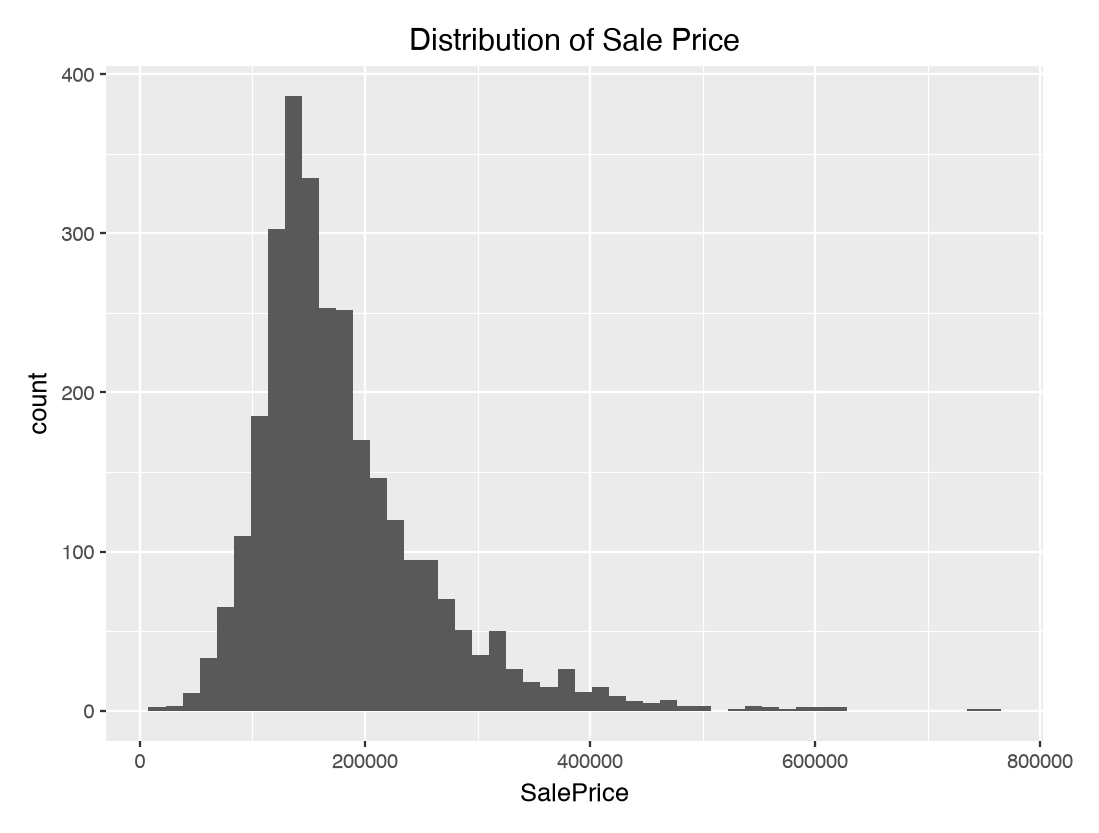

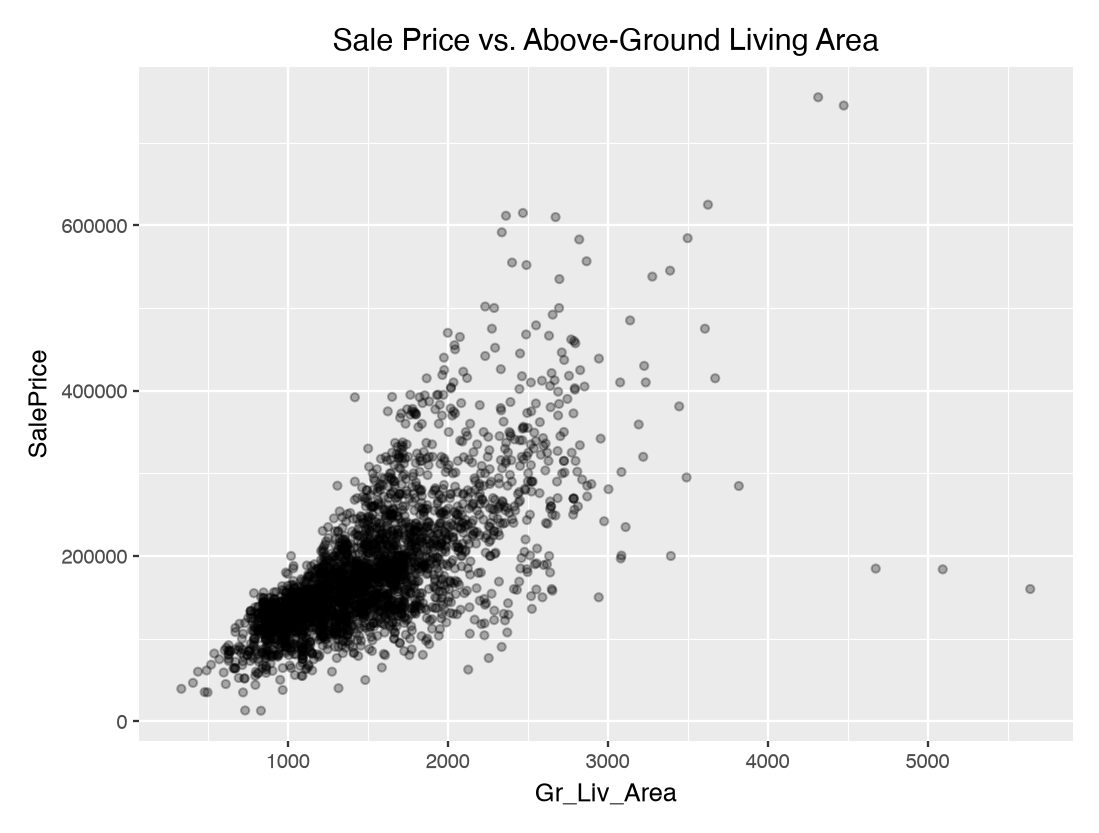

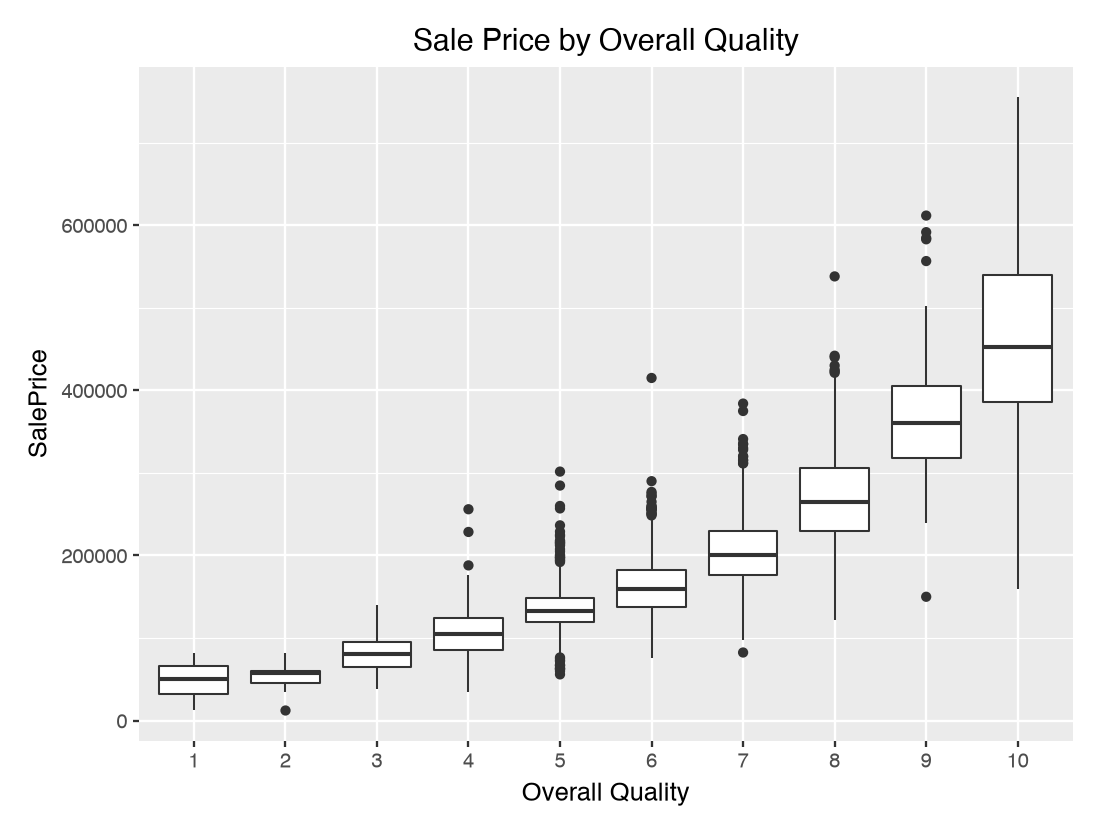

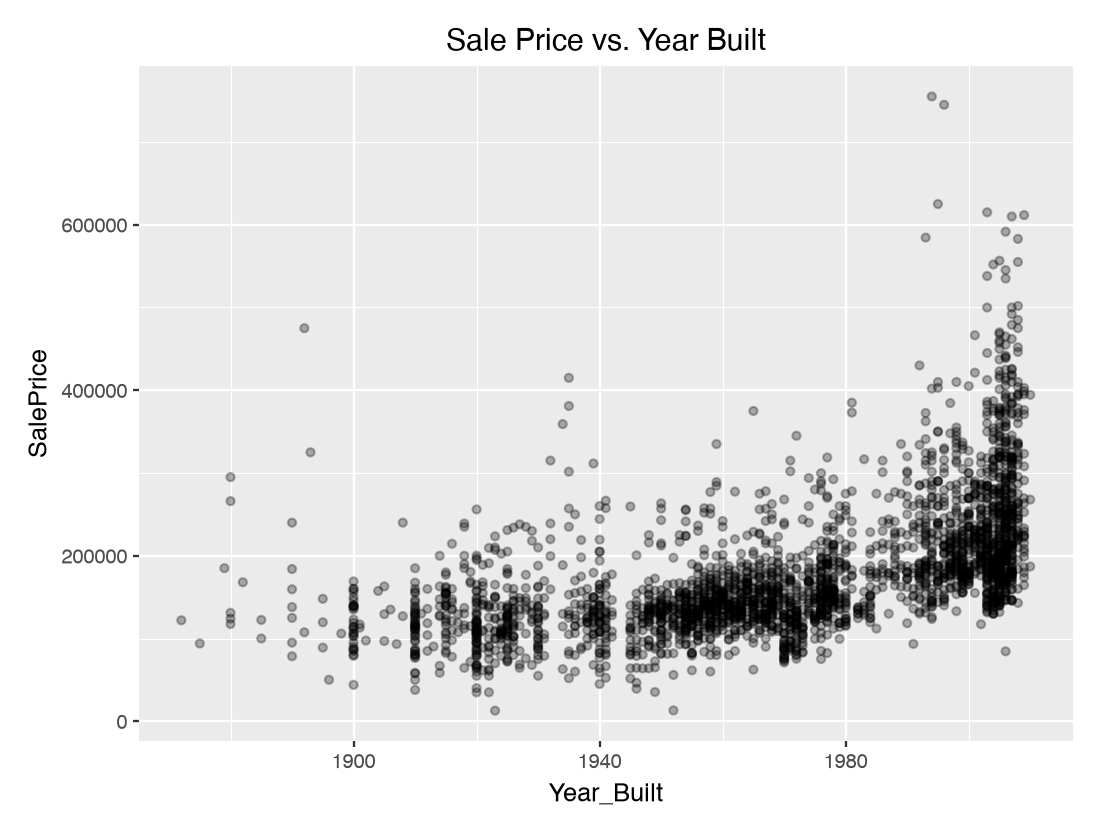

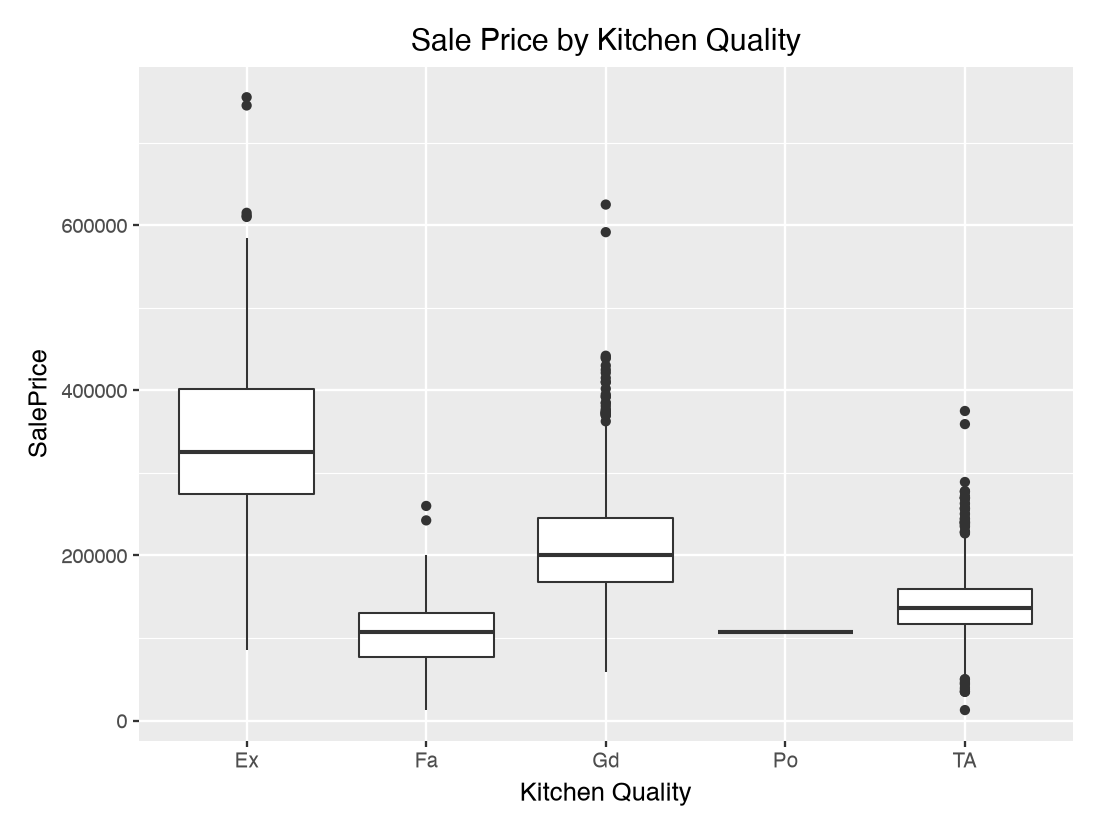

In [35]:
# plotnine can't handle spaces in column names, so rename a copy for plotting
df_plot = df_ames.rename(columns=lambda c: c.replace(" ", "_"))

display(ggplot(df_plot, aes(x="SalePrice")) + geom_histogram(bins=50)
        + labs(title="Distribution of Sale Price"))

display(ggplot(df_plot, aes(x="Gr_Liv_Area", y="SalePrice")) + geom_point(alpha=0.3)
        + labs(title="Sale Price vs. Above-Ground Living Area"))

display(ggplot(df_plot, aes(x="factor(Overall_Qual)", y="SalePrice")) + geom_boxplot()
        + labs(x="Overall Quality", title="Sale Price by Overall Quality"))

display(ggplot(df_plot, aes(x="Year_Built", y="SalePrice")) + geom_point(alpha=0.3)
        + labs(title="Sale Price vs. Year Built"))

display(ggplot(df_plot, aes(x="Kitchen_Qual", y="SalePrice")) + geom_boxplot()
        + labs(x="Kitchen Quality", title="Sale Price by Kitchen Quality"))

In [36]:
# Small feature set chosen from the exploration above
num_small = ["Gr Liv Area", "Overall Qual", "Year Built",
             "Total Bsmt SF", "Garage Cars", "Full Bath"]
cat_small = ["Neighborhood", "Kitchen Qual", "Exter Qual"]

# Large feature set: every column except the target and ID columns
X_all = df_ames.drop(columns=["SalePrice", "Order", "PID"])
num_all = X_all.select_dtypes(include=np.number).columns.tolist()
cat_all = X_all.select_dtypes(exclude=np.number).columns.tolist()

feature_sets = {
    "numeric only":          (num_small, []),
    "numeric + categorical": (num_small, cat_small),
    "all predictors":        (num_all, cat_all),
}

def make_preprocessor(num_cols, cat_cols, poly_degree=None,
                      interaction_only=False, scale=True):
    """Impute missing values, optionally add polynomial/interaction terms,
    optionally standardize numeric columns, and one-hot encode categoricals."""
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if poly_degree:
        num_steps.append(("poly", PolynomialFeatures(degree=poly_degree,
                                                     interaction_only=interaction_only,
                                                     include_bias=False)))
    if scale:
        num_steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(num_steps), num_cols)]
    if cat_cols:
        transformers.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols))
    return ColumnTransformer(transformers, remainder="drop")

# Same 5 shuffled folds for every model, so the comparison is fair
cv = KFold(n_splits=5, shuffle=True, random_state=42)
all_results = []

def cv_rmse(name, model, X):
    scores = cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=cv)
    rmse = np.sqrt(-scores).mean()
    all_results.append({"model": name, "cv_rmse": rmse})
    print(f"{name:65s} ${rmse:,.0f}")
    return rmse

In [37]:
for set_name, (num, cat) in feature_sets.items():
    X = df_ames[num + cat]
    cv_rmse(f"Linear | {set_name}",
            Pipeline([("prep", make_preprocessor(num, cat)),
                      ("lm", LinearRegression())]), X)

    # Polynomial terms only on the small sets (all predictors would give ~700 columns)
    if set_name != "all predictors":
        cv_rmse(f"Linear | {set_name} | interactions",
                Pipeline([("prep", make_preprocessor(num, cat, poly_degree=2, interaction_only=True)),
                          ("lm", LinearRegression())]), X)
        cv_rmse(f"Linear | {set_name} | degree-2 polynomial",
                Pipeline([("prep", make_preprocessor(num, cat, poly_degree=2)),
                          ("lm", LinearRegression())]), X)

Linear | numeric only                                             $37,085
Linear | numeric only | interactions                              $30,375
Linear | numeric only | degree-2 polynomial                       $30,323
Linear | numeric + categorical                                    $32,042
Linear | numeric + categorical | interactions                     $28,075
Linear | numeric + categorical | degree-2 polynomial              $28,061
Linear | all predictors                                           $29,883


In [38]:
for set_name in ["numeric + categorical", "all predictors"]:
    num, cat = feature_sets[set_name]
    X = df_ames[num + cat]
    for k in [1, 3, 5, 10, 15, 25, 50]:
        cv_rmse(f"KNN | {set_name} | k={k}",
                Pipeline([("prep", make_preprocessor(num, cat)),
                          ("knn", KNeighborsRegressor(n_neighbors=k))]), X)

KNN | numeric + categorical | k=1                                 $36,291
KNN | numeric + categorical | k=3                                 $31,157
KNN | numeric + categorical | k=5                                 $30,260
KNN | numeric + categorical | k=10                                $29,827
KNN | numeric + categorical | k=15                                $30,171
KNN | numeric + categorical | k=25                                $30,963
KNN | numeric + categorical | k=50                                $32,161
KNN | all predictors | k=1                                        $38,488
KNN | all predictors | k=3                                        $32,646
KNN | all predictors | k=5                                        $32,073
KNN | all predictors | k=10                                       $32,489
KNN | all predictors | k=15                                       $32,501
KNN | all predictors | k=25                                       $33,574
KNN | all predictors | k=50           

In [39]:
num, cat = feature_sets["numeric + categorical"]
X = df_ames[num + cat]
for depth in [2, 4, 6, 8, 12, None]:
    cv_rmse(f"Tree | numeric + categorical | max_depth={depth}",
            Pipeline([("prep", make_preprocessor(num, cat, scale=False)),
                      ("tree", DecisionTreeRegressor(max_depth=depth, random_state=42))]), X)

for leaf in [5, 10, 20]:
    cv_rmse(f"Tree | numeric + categorical | min_samples_leaf={leaf}",
            Pipeline([("prep", make_preprocessor(num, cat, scale=False)),
                      ("tree", DecisionTreeRegressor(min_samples_leaf=leaf, random_state=42))]), X)

Tree | numeric + categorical | max_depth=2                        $47,950
Tree | numeric + categorical | max_depth=4                        $37,057
Tree | numeric + categorical | max_depth=6                        $34,396
Tree | numeric + categorical | max_depth=8                        $35,078
Tree | numeric + categorical | max_depth=12                       $35,138
Tree | numeric + categorical | max_depth=None                     $35,899
Tree | numeric + categorical | min_samples_leaf=5                 $34,769
Tree | numeric + categorical | min_samples_leaf=10                $33,549
Tree | numeric + categorical | min_samples_leaf=20                $33,382


In [40]:
num, cat = feature_sets["all predictors"]
cv_rmse("Random forest | all predictors | 200 trees",
        Pipeline([("prep", make_preprocessor(num, cat, scale=False)),
                  ("rf", RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                               random_state=42, n_jobs=-1))]),
        df_ames[num + cat])

Random forest | all predictors | 200 trees                        $25,877


np.float64(25877.097960335057)

In [41]:
leaderboard = (pd.DataFrame(all_results)
                 .sort_values("cv_rmse")
                 .reset_index(drop=True))
leaderboard["cv_rmse"] = leaderboard["cv_rmse"].map("${:,.0f}".format)
best = leaderboard.iloc[0]
print(f"Best model: {best['model']}  (estimated test RMSE {best['cv_rmse']})")
leaderboard

Best model: Random forest | all predictors | 200 trees  (estimated test RMSE $25,877)


,model,cv_rmse
0,Random forest | all predictors | 200 trees,"$25,877"
1,Linear | numeric + categorical | degree-2 poly...,"$28,061"
2,Linear | numeric + categorical | interactions,"$28,075"
3,KNN | numeric + categorical | k=10,"$29,827"
4,Linear | all predictors,"$29,883"
5,KNN | numeric + categorical | k=15,"$30,171"
6,KNN | numeric + categorical | k=5,"$30,260"
7,Linear | numeric only | degree-2 polynomial,"$30,323"
8,Linear | numeric only | interactions,"$30,375"
9,KNN | numeric + categorical | k=25,"$30,963"


**Conclusion.** Exploring the data showed that Overall Qual (correlation 0.80), Gr Liv Area, Year Built, basement size and garage size were most related to Sale Price, and that median prices differed a lot by Neighborhood. Using 5-fold cross-validation, I compared 31 models.

- **Linear regression:** Adding categorical predictors helped (numeric only: $37,085; with Neighborhood, Kitchen Qual and Exter Qual: $32,042). Adding polynomial and interaction terms helped even more. The best linear model was numeric + categorical with degree-2 polynomial terms, at $28,061.
- **KNN:** k = 10 was best ($29,827). k = 1 overfit ($36,291) and k = 50 underfit ($32,161). KNN did worse with all predictors than with the smaller feature set, because the many irrelevant columns distort the distances.
- **Decision trees:** Very shallow trees underfit (depth 2: $47,950) and fully grown trees overfit (no depth limit: $35,899). The best single tree used min_samples_leaf = 20, at $33,382.
- **Random forest:** Averaging 200 trees on all predictors gave the lowest estimated test RMSE: **$25,877**.

My best model is the random forest, with an estimated test RMSE of about $25,877.